# IND320 Project work 3

**Author:** Inge Gilje Gunnarshaug

## 1. Introduction

This is the notebook for the third assignment in IND320. The corresponding streamlit app and github repository can be found here:

### Project links

- **GitHub repository:** https://github.com/IngeGiljeGunnarshaug/ind320-inge-gilje-gunnarshaug
- **Streamlit app:** https://ind320-inge-gilje-gunnarshaug.streamlit.app/

## 2. Environment and Imports

In [71]:
from pathlib import Path
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import numpy as np
import pandas as pd
import time
import hashlib
import json
from scipy.fft import dct, idct
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram

## 3. NVE Atlas

### 3.1 Load data

In [2]:
NVE = "https://kart.nve.no/enterprise/rest/services"

LAYERS = {
    "electricity": (
        f"{NVE}/Nettomraader/MapServer/0/query",
        "budomr"
    ),
    "precipitation": (
        f"{NVE}/Mapservices/Administrasjon2/MapServer/0/query",
        "REGION"
    )
}

DATA_DIR = Path("../data")

In [3]:
def load_nve_layer(name: str) -> gpd.GeoDataFrame:
    """Load an NVE geographical layer from cache or download it."""

    if name not in LAYERS:
        raise ValueError(f"Unknown layer: {name}")

    # Create the data directory if necessary
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    file_path = DATA_DIR / f"{name}.geojson"

    # Reuse the downloaded dataset if it already exists
    if file_path.exists():
        print(f"Loading {name} from local file.")
        return gpd.read_file(file_path)

    # Get the API endpoint and region identifier
    url, region_field = LAYERS[name]

    params = {
        "where": "1=1",
        "outFields": region_field,
        "returnGeometry": "true",
        "outSR": 4326,
        "maxAllowableOffset": 0.001,
        "f": "geojson"
    }

    # Download the geographical features
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    data = response.json()

    # Check that the API returned valid GeoJSON
    if data.get("type") != "FeatureCollection":
        raise ValueError(f"Unexpected API response: {data}")

    if not data.get("features"):
        raise ValueError(f"No geographical features returned for {name}")

    # Convert the response to a GeoDataFrame
    gdf = gpd.GeoDataFrame.from_features(
        data["features"],
        crs="EPSG:4326"
    )

    # Save locally for future notebook runs
    gdf.to_file(file_path, driver="GeoJSON")

    print(f"Downloaded {name}: {len(gdf)} features.")
    print(f"Saved to {file_path}")

    return gdf

In [4]:

electricity = load_nve_layer("electricity")
precipitation = load_nve_layer("precipitation")

# Inspect the number of features and region identifiers
print("Electricity areas:")
print(electricity["budomr"].value_counts())

print("\nPrecipitation areas:")
print(precipitation["REGION"].value_counts())


Loading electricity from local file.
Loading precipitation from local file.
Electricity areas:
budomr
NO 1    1
NO 2    1
NO 3    1
NO 4    1
NO 5    1
Name: count, dtype: int64

Precipitation areas:
REGION
RV    1
RM    1
RN    1
RØ    1
RS    1
Name: count, dtype: int64


### 3.2 Visualize geographical boundaries

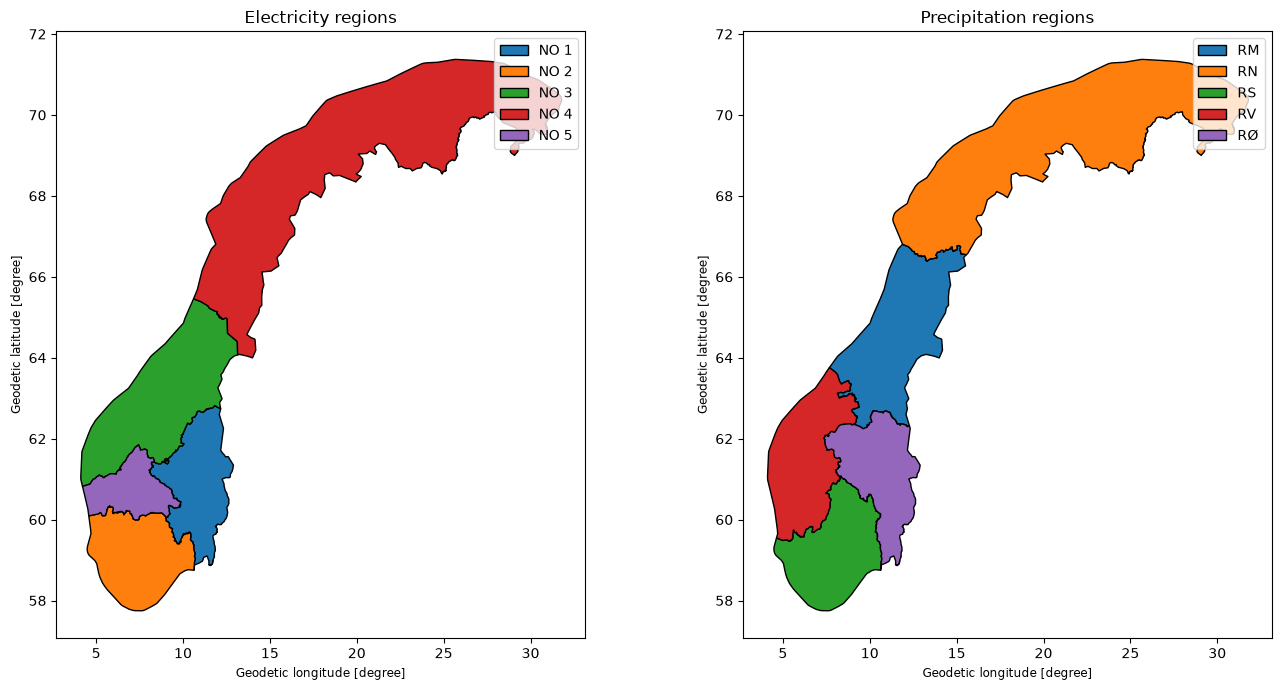

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Electricity regions
electricity.plot(
    ax=axes[0],
    column="budomr",
    legend=True,
    edgecolor="black"
)
axes[0].set_title("Electricity regions")

# Combined precipitation regions
precipitation.plot(
    ax=axes[1],
    column="REGION",
    legend=True,
    edgecolor="black"
)
axes[1].set_title("Precipitation regions")

plt.tight_layout()
plt.show()

### 3.3 Random sampling

In [6]:
def sample_locations(gdf, region_col, n=1000, seed=42):
    """Sample n random locations inside each geographical region."""

    rng = np.random.default_rng(seed)

    # Project to a coordinate system measured in metres
    projected = gdf.to_crs("EPSG:3035")

    samples = []

    for _, row in projected.iterrows():
        polygon = row.geometry
        region = row[region_col]

        minx, miny, maxx, maxy = polygon.bounds
        points = []

        # Rejection sampling: keep only points inside the polygon
        while len(points) < n:
            x = rng.uniform(minx, maxx)
            y = rng.uniform(miny, maxy)

            point = Point(x, y)

            if polygon.contains(point):
                points.append(point)

        for point in points:
            samples.append({
                "REGION": region,
                "geometry": point
            })

    # Convert sampled points back to latitude/longitude
    result = gpd.GeoDataFrame(
        samples,
        geometry="geometry",
        crs="EPSG:3035"
    )

    return result.to_crs("EPSG:4326")

In [7]:

electricity_points = sample_locations(
    electricity, region_col="budomr"
)

precipitation_points = sample_locations(
    precipitation, region_col="REGION"
)

print("Electricity locations:", len(electricity_points))
print("Precipitation locations:", len(precipitation_points))


Electricity locations: 5000
Precipitation locations: 5000


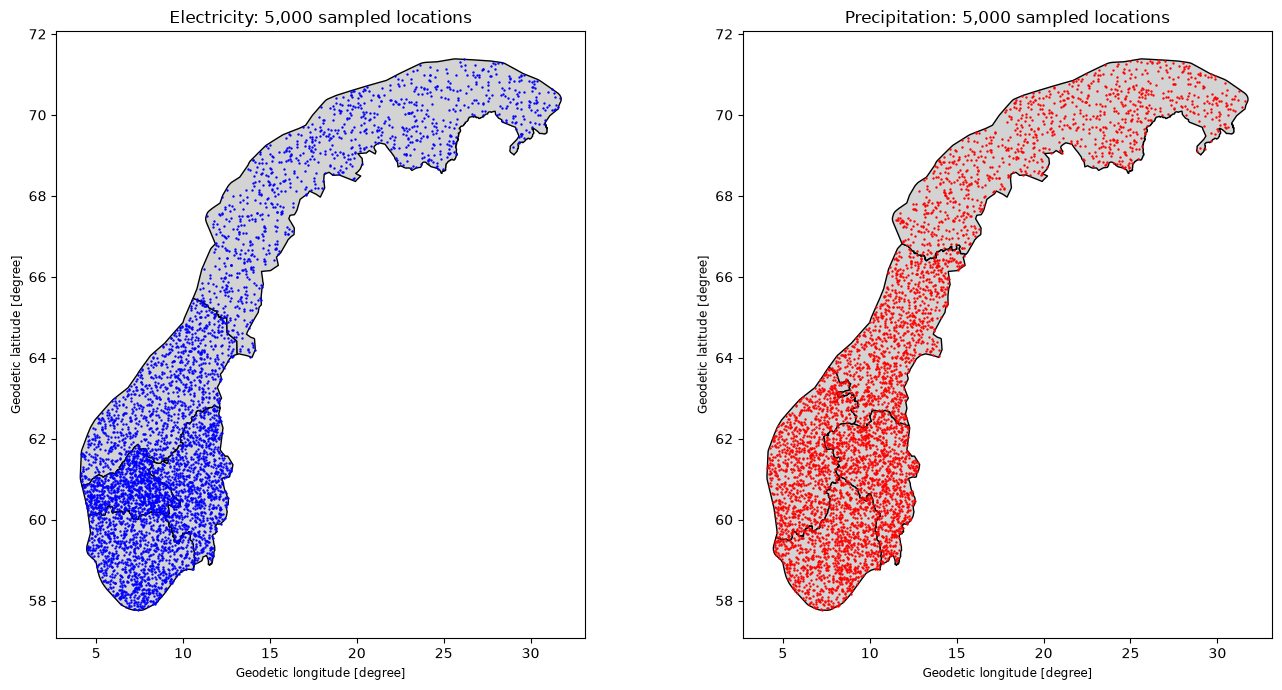

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

electricity.plot(ax=axes[0], color="lightgrey", edgecolor="black")
electricity_points.plot(
    ax=axes[0], markersize=0.5, color="blue"
)
axes[0].set_title("Electricity: 5,000 sampled locations")

precipitation.plot(ax=axes[1], color="lightgrey", edgecolor="black")
precipitation_points.plot(
    ax=axes[1], markersize=0.5, color="red"
)
axes[1].set_title("Precipitation: 5,000 sampled locations")

plt.tight_layout()
plt.show()

### 3.4 Save sampled locations

In [9]:
# Convert GeoDataFrames to regular DataFrames with coordinates
def points_to_dataframe(gdf, area_type):
    return pd.DataFrame({
        "area_type": area_type,
        "region": gdf["REGION"],
        "latitude": gdf.geometry.y,
        "longitude": gdf.geometry.x
    })

# Combine electricity and precipitation locations
locations = pd.concat([
    points_to_dataframe(electricity_points, "electricity"),
    points_to_dataframe(precipitation_points, "precipitation")
], ignore_index=True)

# Save all locations to one CSV file
file_path = DATA_DIR / "sampled_locations.csv"
locations.to_csv(file_path, index=False)

print(f"Saved {len(locations)} locations to {file_path}")
display(locations.head())

Saved 10000 locations to ../data/sampled_locations.csv


,area_type,region,latitude,longitude
0,electricity,NO 1,60.540200,11.725407
1,electricity,NO 1,61.588228,12.197488
2,electricity,NO 1,61.956291,11.739333
3,electricity,NO 1,62.111669,11.162875
4,electricity,NO 1,59.687971,10.151264


## 4. open-meteo API
### 4.1 Remove redundant areas

In [10]:
def reduce_locations(locations, region, cell_size=25000):
    """Select one sampled location per approximate spatial grid cell."""

    # Filter the requested electricity region
    subset = locations.loc[
        (locations["area_type"] == "electricity") &
        (locations["region"] == region)
    ].copy()

    if subset.empty:
        raise ValueError(f"No locations found for {region}")

    # Convert longitude/latitude into projected coordinates
    gdf = gpd.GeoDataFrame(
        subset,
        geometry=gpd.points_from_xy(
            subset["longitude"], subset["latitude"]
        ),
        crs="EPSG:4326"
    ).to_crs("EPSG:3035")

    # Assign each point to a 25 km square cell
    gdf["grid_x"] = np.floor(gdf.geometry.x / cell_size).astype(int)
    gdf["grid_y"] = np.floor(gdf.geometry.y / cell_size).astype(int)

    # Keep one original sampled coordinate from each occupied cell
    reduced = gdf.drop_duplicates(
        subset=["grid_x", "grid_y"]
    ).copy()

    return reduced.to_crs("EPSG:4326").reset_index(drop=True)

In [11]:

no3_locations = reduce_locations(locations, "NO 3")

print("Original locations:", 1000)
print("Reduced locations:", len(no3_locations))

display(no3_locations[["latitude", "longitude"]].head())

Original locations: 1000
Reduced locations: 187


,latitude,longitude
0,62.791983,10.298134
1,62.392418,5.101840
2,62.377929,5.960484
3,61.401061,5.922214
4,62.545520,8.641251


### 4.2 Download function

In [12]:
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"

WEATHER_VARIABLES = [
    "temperature_2m",
    "precipitation",
    "rain",
    "snowfall",
    "relative_humidity_2m",
    "wind_speed_10m",
    "shortwave_radiation",
    "et0_fao_evapotranspiration"
]

WEATHER_DIR = Path("../data/weather")
WEATHER_DIR.mkdir(parents=True, exist_ok=True)

def download_weather(region, start_date, end_date, limit=None, batch_size=5):
    """Download ERA5 weather data with automatic caching and resuming."""

    points = reduce_locations(locations, region)

    if limit is not None:
        points = points.head(limit)

    if points.empty:
        raise ValueError(f"No locations found for {region}")

    # Identify the exact request configuration for safe cache reuse
    config = {
        "region": region,
        "start_date": start_date,
        "end_date": end_date,
        "batch_size": batch_size,
        "coordinates": points[["latitude", "longitude"]].values.tolist(),
        "variables": WEATHER_VARIABLES,
        "model": "era5",
        "elevation": "nan",
        "cell_selection": "nearest",
        "timezone": "GMT"
    }

    config_hash = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode()
    ).hexdigest()[:12]

    cache_dir = WEATHER_DIR / f"{region.replace(' ', '')}_{config_hash}"
    cache_dir.mkdir(parents=True, exist_ok=True)

    results = []

    for start in range(0, len(points), batch_size):
        batch = points.iloc[start:start + batch_size]
        batch_path = cache_dir / f"batch_{start // batch_size:04d}.pkl"

        # Load an existing batch instead of downloading it again
        if batch_path.exists():
            print(f"Loading cached {batch_path.name}")
            results.append(pd.read_pickle(batch_path))
            continue

        params = {
            "latitude": ",".join(batch["latitude"].astype(str)),
            "longitude": ",".join(batch["longitude"].astype(str)),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ",".join(WEATHER_VARIABLES),
            "models": "era5",
            "timezone": "GMT",
            "cell_selection": "nearest",
            "elevation": ",".join(["nan"] * len(batch))
        }

        # Retry temporary failures, but avoid very long waits
        for attempt in range(5):
            response = requests.get(
                OPEN_METEO_URL,
                params=params,
                timeout=120
            )

            if response.status_code in (429, 500, 502, 503, 504):
                if attempt == 4:
                    response.raise_for_status()

                retry_after = response.headers.get("Retry-After")
                try:
                    server_wait = float(retry_after) if retry_after else 0
                except ValueError:
                    server_wait = 0

                wait = max(2 ** (attempt + 1), server_wait)

                if wait > 120:
                    raise RuntimeError(
                        f"API rate limit reached. "
                        f"Requested wait: {wait / 3600:.2f} hours. "
                        f"Completed batches are saved in {cache_dir}"
                    )

                print(f"HTTP {response.status_code}. Retrying in {wait:.0f}s...")
                time.sleep(wait)
                continue

            if not response.ok:
                print("Status:", response.status_code)
                print("API response:", response.text)
                response.raise_for_status()

            break

        data = response.json()

        if isinstance(data, dict):
            data = [data]

        if len(data) != len(batch):
            raise ValueError("API returned an unexpected number of locations")

        batch_results = []

        for batch_index, (_, point) in enumerate(batch.iterrows()):
            
            location_id = start + batch_index
            item = data[batch_index]
            df = pd.DataFrame(item["hourly"])

            df["region"] = region
            df["location_id"] = location_id
            df["requested_latitude"] = point["latitude"]
            df["requested_longitude"] = point["longitude"]
            df["grid_latitude"] = item["latitude"]
            df["grid_longitude"] = item["longitude"]

            batch_results.append(df)

        batch_df = pd.concat(batch_results, ignore_index=True)

        # Save atomically so interruptions cannot leave partial cache files
        temp_path = batch_path.with_suffix(".tmp")
        batch_df.to_pickle(temp_path)
        temp_path.replace(batch_path)

        results.append(batch_df)

        print(f"Saved batch {start // batch_size + 1} to {batch_path}")

        time.sleep(2)

    return pd.concat(results, ignore_index=True)


### 4.3 Test function using 5 locations

In [39]:
test_weather = download_weather(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-01-03",
    limit=5
)

print("Rows downloaded:", len(test_weather))
print("Locations:", test_weather["location_id"].nunique())

display(test_weather.head())

Saved batch 1 to ../data/weather/NO3_cd3a4cf17b0b/batch_0000.pkl
Rows downloaded: 360
Locations: 5


,time,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,shortwave_radiation,et0_fao_evapotranspiration,region,location_id,requested_latitude,requested_longitude,grid_latitude,grid_longitude
0,2024-01-01T00:00,-9.2,0.0,0.0,0.0,75,24.8,0.0,0.02,NO 3,0,62.791983,10.298134,62.75,10.25
1,2024-01-01T01:00,-9.1,0.0,0.0,0.0,75,25.3,0.0,0.02,NO 3,0,62.791983,10.298134,62.75,10.25
2,2024-01-01T02:00,-8.9,0.0,0.0,0.0,75,26.5,0.0,0.02,NO 3,0,62.791983,10.298134,62.75,10.25
3,2024-01-01T03:00,-8.7,0.0,0.0,0.0,75,26.6,0.0,0.02,NO 3,0,62.791983,10.298134,62.75,10.25
4,2024-01-01T04:00,-8.5,0.0,0.0,0.0,74,26.5,0.0,0.02,NO 3,0,62.791983,10.298134,62.75,10.25


In [40]:

# Convert timestamps to datetime
test_weather["time"] = pd.to_datetime(test_weather["time"])

# Check hourly coverage and missing values
print("Time range:")
print(test_weather["time"].min(), "to", test_weather["time"].max())

print("\nMissing values:")
print(test_weather[WEATHER_VARIABLES].isna().sum())

# Check the number of observations per location
print("\nObservations per location:")
print(test_weather.groupby("location_id").size())

# Check for duplicate grid-cell coordinates
print("\nUnique returned grid cells:")
print(
    test_weather[
        ["grid_latitude", "grid_longitude"]
    ].drop_duplicates().shape[0]
)


Time range:
2024-01-01 00:00:00 to 2024-01-03 23:00:00

Missing values:
temperature_2m                0
precipitation                 0
rain                          0
snowfall                      0
relative_humidity_2m          0
wind_speed_10m                0
shortwave_radiation           0
et0_fao_evapotranspiration    0
dtype: int64

Observations per location:
location_id
0    72
1    72
2    72
3    72
4    72
dtype: int64

Unique returned grid cells:
5


### 4.4 Download data for NO3 for 2024

In [44]:
no3_weather = download_weather(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    batch_size=5
)

print("Total observations:", len(no3_weather))
print("Unique locations:", no3_weather["location_id"].nunique())

Loading cached batch_0000.pkl
Saved batch 2 to ../data/weather/NO3_84a0412011f9/batch_0001.pkl
Saved batch 3 to ../data/weather/NO3_84a0412011f9/batch_0002.pkl
Saved batch 4 to ../data/weather/NO3_84a0412011f9/batch_0003.pkl
Saved batch 5 to ../data/weather/NO3_84a0412011f9/batch_0004.pkl
Saved batch 6 to ../data/weather/NO3_84a0412011f9/batch_0005.pkl
Saved batch 7 to ../data/weather/NO3_84a0412011f9/batch_0006.pkl
HTTP 429. Retrying in 9s...
Saved batch 8 to ../data/weather/NO3_84a0412011f9/batch_0007.pkl
Saved batch 9 to ../data/weather/NO3_84a0412011f9/batch_0008.pkl
Saved batch 10 to ../data/weather/NO3_84a0412011f9/batch_0009.pkl
Saved batch 11 to ../data/weather/NO3_84a0412011f9/batch_0010.pkl
Saved batch 12 to ../data/weather/NO3_84a0412011f9/batch_0011.pkl
Saved batch 13 to ../data/weather/NO3_84a0412011f9/batch_0012.pkl
HTTP 429. Retrying in 44s...
Saved batch 14 to ../data/weather/NO3_84a0412011f9/batch_0013.pkl
Saved batch 15 to ../data/weather/NO3_84a0412011f9/batch_0014.p

## 5. Outliers and anomalies
### 5.1 Load cahced data

In [13]:
WEATHER_DIR = Path("../data/weather")

def load_weather(cache_name):
    """Load and combine cached ERA5 weather batches."""

    cache_dir = WEATHER_DIR / cache_name

    # Find all saved batch files
    batch_files = sorted(cache_dir.glob("batch_*.pkl"))

    if not batch_files:
        raise FileNotFoundError(
            f"No cached weather batches found in {cache_dir}"
        )

    # Load each batch and combine into one DataFrame
    weather = pd.concat(
        [pd.read_pickle(file) for file in batch_files],
        ignore_index=True
    )

    # Convert timestamps to datetime and sort chronologically
    weather["time"] = pd.to_datetime(weather["time"])
    weather = weather.sort_values(
        ["time", "location_id"]
    ).reset_index(drop=True)

    print(f"Loaded {len(batch_files)} batches")
    print(f"Total observations: {len(weather):,}")
    print(f"Unique locations: {weather['location_id'].nunique()}")
    print(f"Period: {weather['time'].min()} to {weather['time'].max()}")

    return weather

In [14]:
no3_weather = load_weather("NO3_84a0412011f9")

display(no3_weather.head())

Loaded 38 batches
Total observations: 1,642,608
Unique locations: 187
Period: 2024-01-01 00:00:00 to 2024-12-31 23:00:00


,time,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,shortwave_radiation,et0_fao_evapotranspiration,region,location_id,requested_latitude,requested_longitude,grid_latitude,grid_longitude
0,2024-01-01,-9.2,0.0,0.0,0.0,75,24.8,0.0,0.02,NO 3,0,62.791983,10.298134,62.75,10.25
1,2024-01-01,5.2,0.0,0.0,0.0,68,20.3,0.0,0.04,NO 3,1,62.392418,5.101840,62.50,5.00
2,2024-01-01,2.1,0.0,0.0,0.0,66,23.8,0.0,0.04,NO 3,2,62.377929,5.960484,62.50,6.00
3,2024-01-01,0.6,0.0,0.0,0.0,66,10.2,0.0,0.02,NO 3,3,61.401061,5.922214,61.50,6.00
4,2024-01-01,-9.1,0.0,0.0,0.0,75,11.9,0.0,0.01,NO 3,4,62.545520,8.641251,62.50,8.75


### 5.2 Average hourly precipitation

In [15]:
# Calculate spatial average precipitation for each hour
hourly_weather = (
    no3_weather
    .groupby("time")
    .agg(
        precipitation=("precipitation", "mean"),
        temperature=("temperature_2m", "mean")
    )
    .sort_index()
)

print(f"Hourly observations: {len(hourly_weather)}")

Hourly observations: 8784


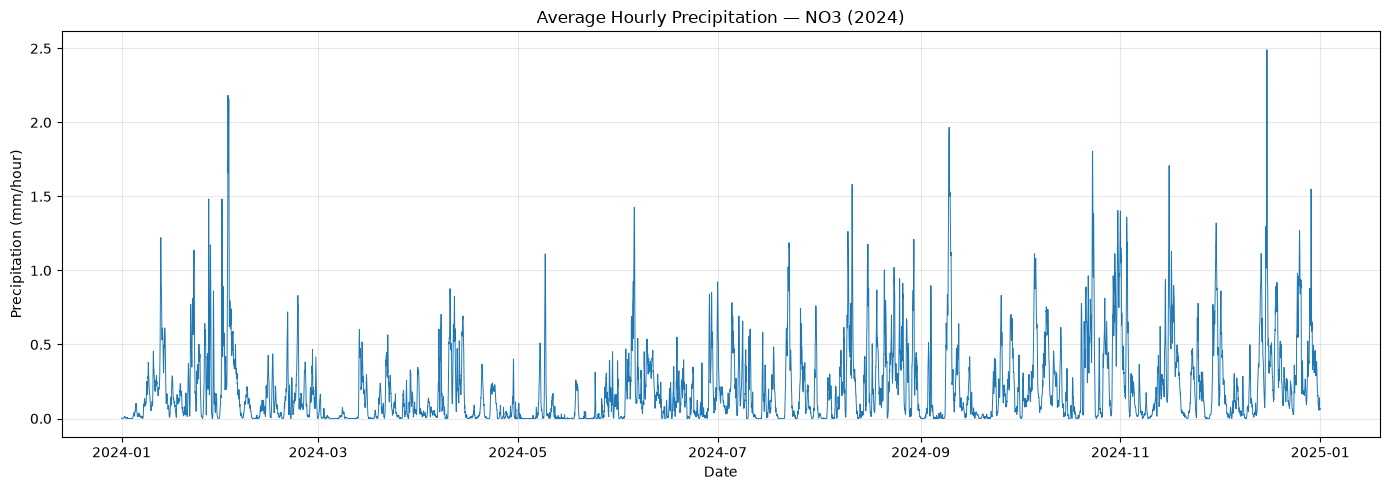

In [16]:

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    hourly_weather.index,
    hourly_weather["precipitation"],
    linewidth=0.7
)

ax.set(
    title="Average Hourly Precipitation — NO3 (2024)",
    xlabel="Date",
    ylabel="Precipitation (mm/hour)"
)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The precipitation is fluctuating throughout the year, but the size of the peaks is varying during the different seasons. The peaks are high during winter and autumn, and lower during spring and summer.

### 5.3 High-pass filtering for precipitation

In [17]:
def dct_highpass(series, cutoff=30):
    """Remove the lowest-frequency DCT components from a time series."""

    values = np.asarray(series, dtype=float)

    # Transform the time series into DCT coefficients
    coefficients = dct(values, norm="ortho")

    # Remove the lowest-frequency components
    coefficients[:cutoff] = 0

    # Reconstruct the high-frequency residual
    residual = idct(coefficients, norm="ortho")

    return residual

In [18]:
precipitation = hourly_weather["precipitation"]

# Calculate the high-frequency residual
residual = dct_highpass(precipitation, cutoff=30)

# Recover the slowly varying baseline
baseline = precipitation.to_numpy() - residual

print("Original mean:", precipitation.mean())
print("Residual mean:", residual.mean())
print("Residual standard deviation:", residual.std())

Original mean: 0.202231025296358
Residual mean: -2.275047181608927e-18
Residual standard deviation: 0.24428584245508392


In [19]:
def robust_spc(residual, baseline, n_std=3):
    """Calculate robust SPC boundaries and identify outliers."""

    # Estimate the centre and scale from the full-year residuals
    median = np.median(residual)
    mad = np.median(np.abs(residual - median))
    robust_std = 1.4826 * mad

    # Construct boundaries on the original precipitation scale
    upper = baseline + median + n_std * robust_std
    lower = baseline + median - n_std * robust_std

    # Identify observations outside the boundaries
    outliers = (residual > median + n_std * robust_std) | (
        residual < median - n_std * robust_std
    )

    return lower, upper, outliers, robust_std

In [70]:
lower, upper, outliers, robust_std = robust_spc(
    residual,
    baseline,
    n_std=3
)

print(f"Robust standard deviation: {robust_std:.4f}")
print(f"Number of outliers: {outliers.sum()}")
print(f"Percentage of outliers: {outliers.mean() * 100:.2f}%")

Robust standard deviation: 0.1454
Number of outliers: 623
Percentage of outliers: 7.09%


In [ ]:
def plot_precipitation_outliers(weather, cutoff=100, n_std=3):
    """Plot average precipitation with DCT-based robust SPC limits."""

    # Extract the original precipitation series
    precipitation = weather["precipitation"]
    values = precipitation.to_numpy()

    # Remove low-frequency variation using the DCT
    residual = dct_highpass(values, cutoff=cutoff)
    baseline = values - residual

    # Calculate robust SPC limits
    lower, upper, outliers, robust_std = robust_spc(
        residual, baseline, n_std=n_std
    )

    # Store detected outliers with their original precipitation values
    outlier_df = pd.DataFrame({
        "time": precipitation.index[outliers],
        "precipitation": values[outliers],
        "lower_limit": lower[outliers],
        "upper_limit": upper[outliers]
    })

    # Plot the original precipitation and SPC boundaries
    fig, ax = plt.subplots(figsize=(15, 5))

    ax.plot(
        precipitation.index,
        values,
        color="steelblue",
        linewidth=0.7,
        label="Average precipitation"
    )

    ax.plot(
        precipitation.index,
        upper,
        color="darkorange",
        linestyle="--",
        linewidth=1,
        label="Upper control limit"
    )

    ax.plot(
        precipitation.index,
        lower,
        color="darkorange",
        linestyle="--",
        linewidth=1,
        label="Lower control limit"
    )

    # Highlight outliers using the original precipitation values
    ax.scatter(
        precipitation.index[outliers],
        values[outliers],
        color="red",
        s=12,
        zorder=3,
        label="Outliers"
    )

    ax.set(
        title=f"NO3 Precipitation Outliers — DCT cutoff={cutoff}, k={n_std}",
        xlabel="Date",
        ylabel="Average precipitation (mm/hour)"
    )

    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    # Print summary statistics
    print(f"Robust standard deviation: {robust_std:.4f}")
    print(f"Number of outliers: {outliers.sum()}")
    print(f"Outlier percentage: {outliers.mean() * 100:.2f}%")

    return fig, outlier_df


Robust standard deviation: 0.1312
Number of outliers: 529
Outlier percentage: 6.02%


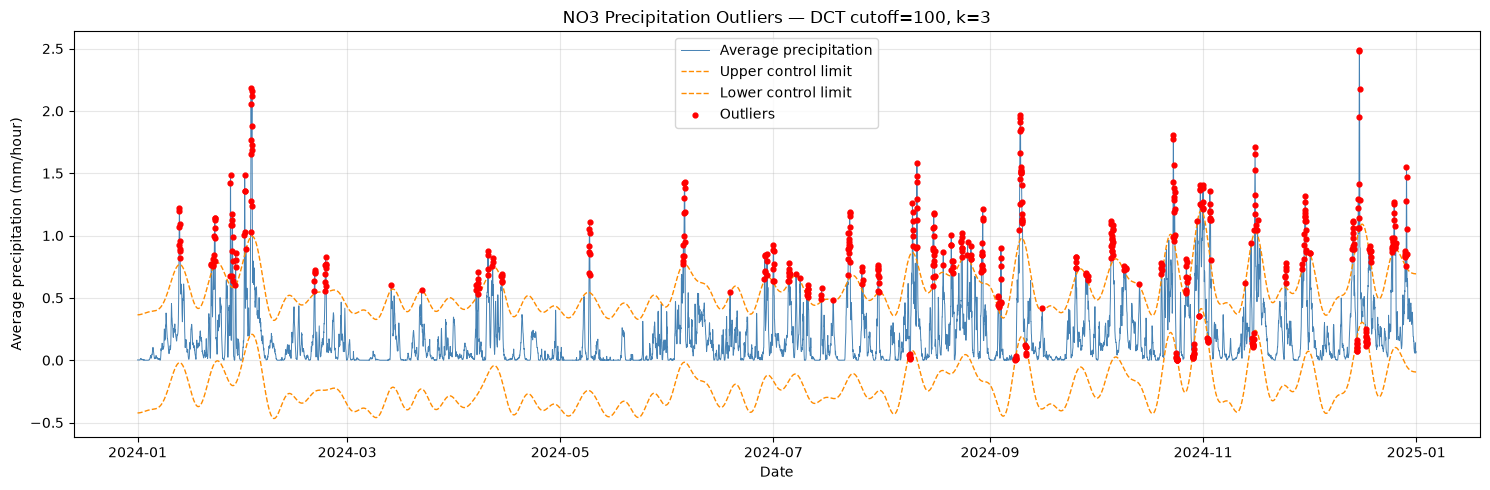

In [27]:

fig, precipitation_outliers = plot_precipitation_outliers(
    hourly_weather,
    cutoff=100,
    n_std=3
)

plt.show()

Most of the lower control limit is below 0, and since negative precipitation values are impossible it is meaningless. Having said that there are a few times where the lower limit is above 0 and catch some outliers, although most are above the upper limit. 

### 5.4 Temperature anomalies

In [23]:
def plot_temperature_anomalies(weather, contamination=0.01, n_neighbors=20):
    """Detect and plot temperature anomalies using Local Outlier Factor."""

    # Extract the spatially averaged temperature series
    temperature = weather["temperature"].dropna()

    # LOF expects a 2D feature matrix
    X = temperature.to_numpy().reshape(-1, 1)

    # Fit LOF and classify observations
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    labels = lof.fit_predict(X)
    anomalies = labels == -1

    # Store anomalous observations and their LOF scores
    anomaly_df = pd.DataFrame({
        "time": temperature.index[anomalies],
        "temperature": temperature.to_numpy()[anomalies],
        "lof_score": -lof.negative_outlier_factor_[anomalies]
    })

    # Plot the original temperature series
    fig, ax = plt.subplots(figsize=(15, 5))

    ax.plot(
        temperature.index,
        temperature,
        color="steelblue",
        linewidth=0.7,
        label="Average temperature"
    )

    # Highlight anomalous observations
    ax.scatter(
        temperature.index[anomalies],
        temperature.to_numpy()[anomalies],
        color="red",
        s=15,
        zorder=3,
        label="LOF anomalies"
    )

    ax.set(
        title=f"NO3 Temperature Anomalies — LOF ({contamination:.1%})",
        xlabel="Date",
        ylabel="Average temperature (°C)"
    )

    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()

    # Print summary statistics
    print(f"Total observations: {len(temperature)}")
    print(f"Detected anomalies: {anomalies.sum()}")
    print(f"Anomaly percentage: {anomalies.mean() * 100:.2f}%")

    return fig, anomaly_df

Total observations: 8784
Detected anomalies: 88
Anomaly percentage: 1.00%


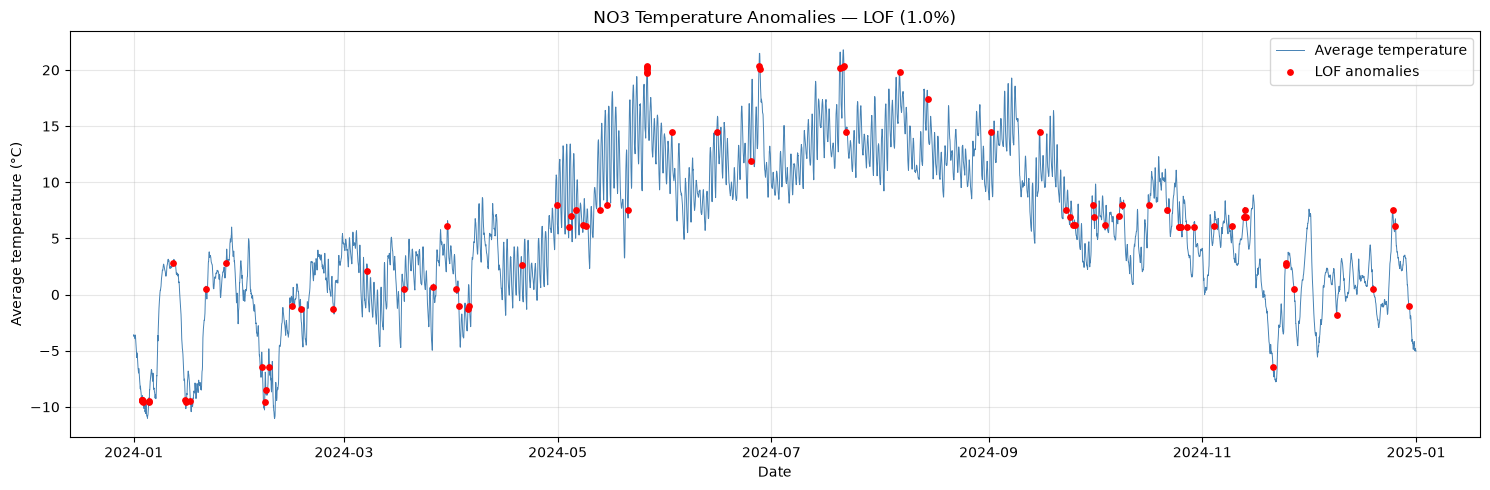

In [69]:
fig, temperature_anomalies = plot_temperature_anomalies(
    hourly_weather,
    contamination=0.01
)

plt.show()

Anomalies are occuring throughout the year. Some of the anomalies are at temperature extremes, while others are at seemingly regular temperatures. 

## 6. Seasonal-Trend Decomposition using LOESS
### 6.1 Load data

In [55]:
# Load in magasinstatistikk data
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=60)
response.raise_for_status()

data = pd.DataFrame(response.json())
data["dato_Id"] = pd.to_datetime(data["dato_Id"])

In [63]:
# Filter relevant parts
reservoirs = (
    data[(data["omrType"] == "EL") & (data["omrnr"] == 3)]
    .set_index("dato_Id")[["fyllingsgrad"]]
    .sort_index()
    .rename(columns={"fyllingsgrad": "fill_ratio"})
)

# Print summary statistics
print(len(reservoirs))
print(f"{reservoirs.index.min().date()} to {reservoirs.index.max().date()}")
reservoirs.head()

1661
1995-01-08 to 2026-11-01


,fill_ratio
dato_Id,
1995-01-08,0.602376
1995-01-15,0.569943
1995-01-22,0.542203
1995-01-29,0.508148
1995-02-05,0.473883


### 6.2 STL

In [65]:

def plot_stl(series, seasonal=13, trend=105, robust=True):
    """Decompose weekly reservoir filling into trend, seasonality and residuals."""

    # Prepare the time series
    series = series.sort_index().dropna().copy()
    series.index = pd.to_datetime(series.index)

    # Fit STL using an annual seasonal period of 52 weeks
    model = STL(
        series,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = model.fit()

    # Create the decomposition plot
    fig = result.plot()
    fig.set_size_inches(14, 9)

    fig.suptitle(
        f"STL Decomposition of Reservoir Filling "
        f"(seasonal={seasonal}, trend={trend}, robust={robust})",
        fontsize=14
    )

    fig.tight_layout()

    return fig


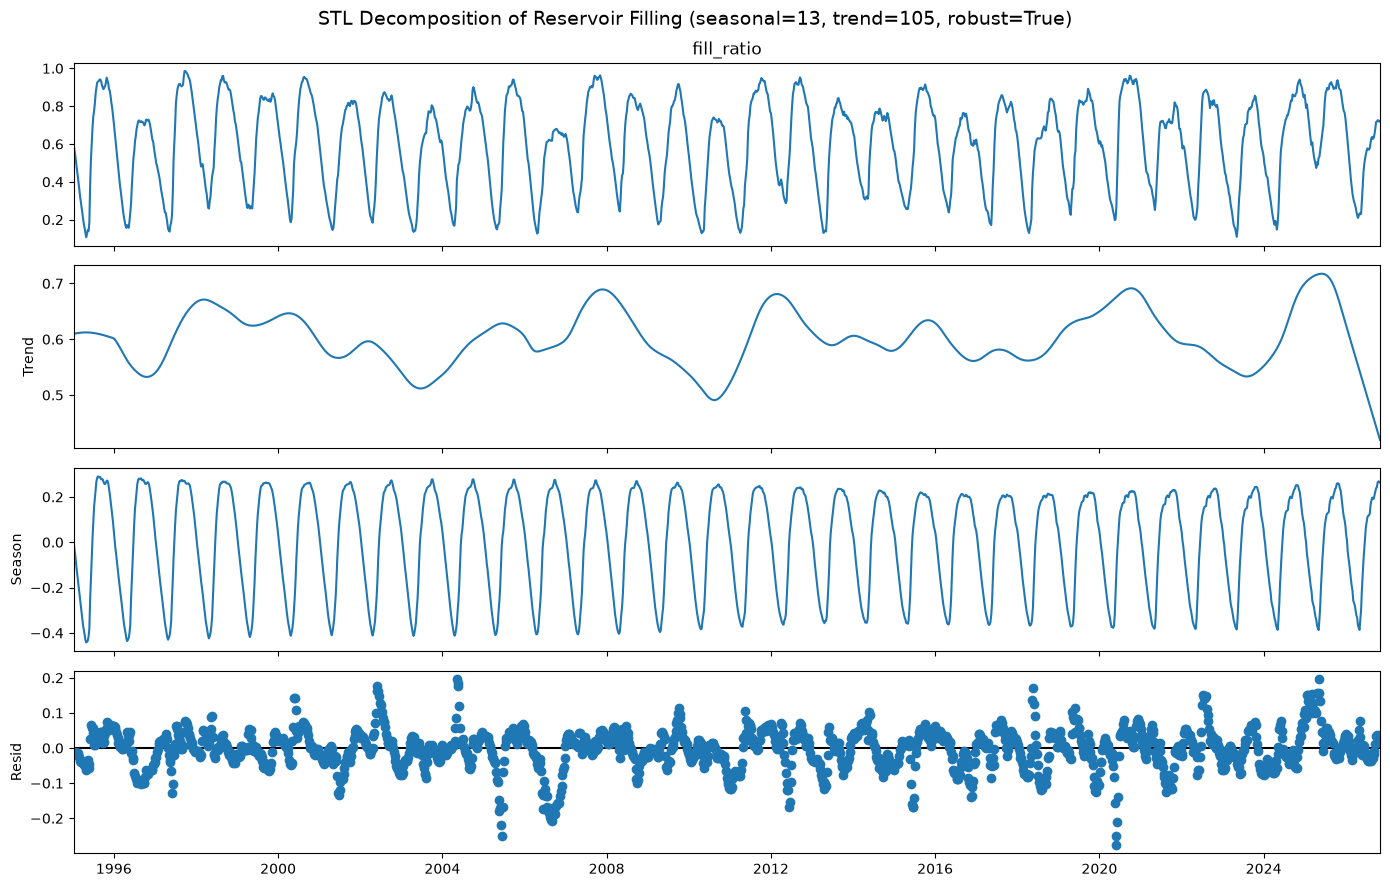

In [ ]:
fig = plot_stl(
    reservoirs["fill_ratio"],
    seasonal=13,
    trend=105,
    robust=True
)

plt.show()

The STL decomposition shows clear seasonality with lows early spring and peaks late autumn every year. The trend part is varying aroung 50%-70% with a large drop at the end. The residual is mostly 0 with a few small deviations, probably due to unusual fillings.

## 7. Spectrogram
### 7.1 Function implementation

In [80]:
def plot_spectrogram(series, window_length=156, overlap=130):
    """Plot the spectrogram of weekly reservoir filling data."""

    # Prepare and validate the time series
    series = series.copy().sort_index()
    series.index = pd.to_datetime(series.index)

    if series.isna().any():
        raise ValueError("The time series contains missing values.")

    if not series.index.to_series().diff().dropna().eq(
        pd.Timedelta(weeks=1)
    ).all():
        raise ValueError("The time series must have weekly observations.")

    if not (0 <= overlap < window_length <= len(series)):
        raise ValueError("Require 0 <= overlap < window_length <= series length.")

    # Compute the spectrogram using one observation per week
    frequencies, times, power = spectrogram(
        series.to_numpy(),
        fs=52.0,
        window="hann",
        nperseg=window_length,
        noverlap=overlap,
        detrend="linear",
        scaling="spectrum",
        mode="psd"
    )

    # Convert window-centre offsets into calendar dates
    dates = series.index[0] + pd.to_timedelta(times * 52, unit="W")

    # Convert power to decibels for better visualization
    power_db = 10 * np.log10(np.maximum(power, 1e-12))

    # Plot the time-frequency representation
    fig, ax = plt.subplots(figsize=(14, 6))

    mesh = ax.pcolormesh(
        dates,
        frequencies,
        power_db,
        shading="auto",
        cmap="viridis"
    )

    # Reference line for annual seasonality
    ax.axhline(
        1,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Annual cycle (1 cycle/year)"
    )

    ax.set(
        title="Spectrogram of Reservoir Filling",
        xlabel="Year",
        ylabel="Frequency (cycles/year)"
    )

    ax.set_ylim(0, 4)
    ax.set_yticks(np.arange(0, 5, 1))
    ax.legend()

    fig.colorbar(
        mesh,
        ax=ax,
        label="Power (dB)"
    )

    fig.tight_layout()

    return fig

### 7.2 Apply function

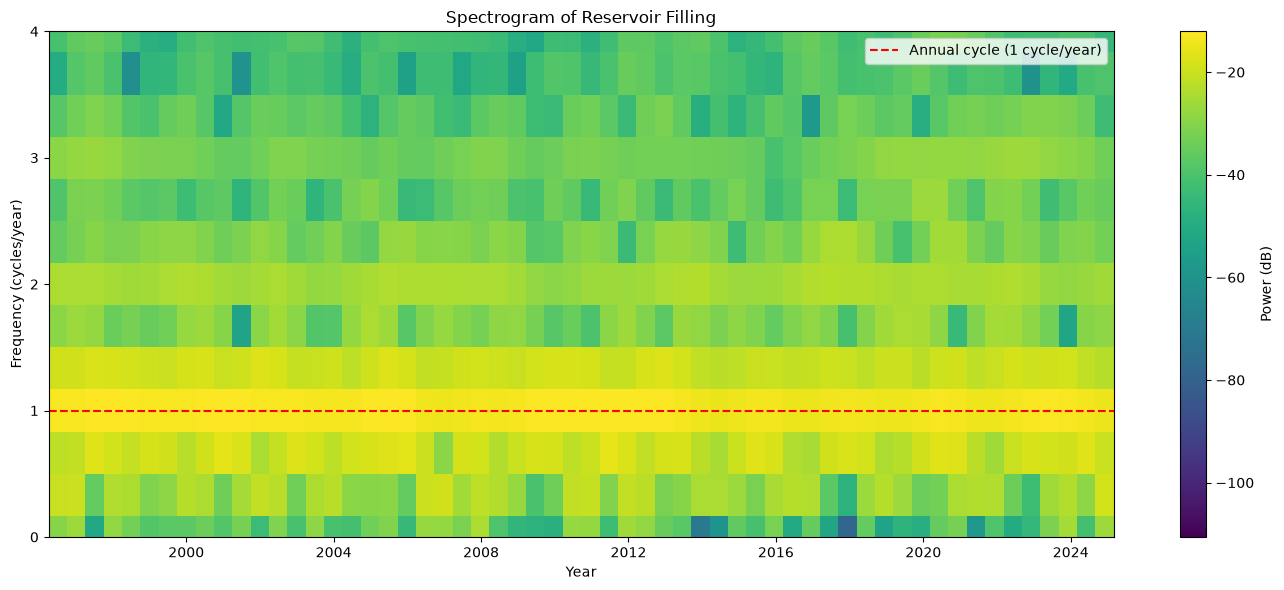

In [81]:
fig = plot_spectrogram(
    reservoirs["fill_ratio"],
    window_length=156,
    overlap=130
)

plt.show()

There is a clear line at frequency 1, meaning 1 cycle per year. There are also some high values around 1 possibly due to small yearly variations in amplitude.

## 8. AI & Log
### 8.1 AI usage

I used GPT-6 for coding.

### 8.2 Log

I started the assignment by working on the Jupyter Notebook first. The notebook was fairly straightforward, with only a few issues during the downloading of Open-Meteo data. I received HTTP 429 errors a couple of times because of too many requests to the API. To solve this, I used GPT-6 to help optimize the downloading function by splitting the requests into smaller batches and adding better handling of the API limitations. After some adjustments, I managed to download the data and complete the required analyses.

The main feedback I received from assignment 2 was to make the slider control the interval downloaded from NVE, rather than downloading all the data and filtering it afterwards. I tried to implement this, but was unable to get it working properly. It seemed that the API did not respond to the date parameters as expected.

After trying to fix this issue, I moved on to improving the structure of the Streamlit application. I merged the NVE table page and plots page into one page using tabs. This also meant that I did not need the global area type selector and instead use a local selector on the NVE page, making the application simpler.

Next, I created the two new required pages for STL/spectrogram analysis and outlier/anomaly detection. To keep the code organized, I created two additional helper files. The first, weather_utils.py, handles downloading, caching and preparing the Open-Meteo data. The second, analysis_utils.py, contains the functions used for the different statistical analyses and plots. I also removed the separate meteorological data page, since the relevant data was already displayed in the outlier/anomaly page.

Lastly, I updated requirements.txt with the necessary dependencies and merged the assignment3 branch into the main branch on GitHub. I tried to use version control throughout the assignment, but occasionally forgot to commit changes, mainly while working on the notebook.
